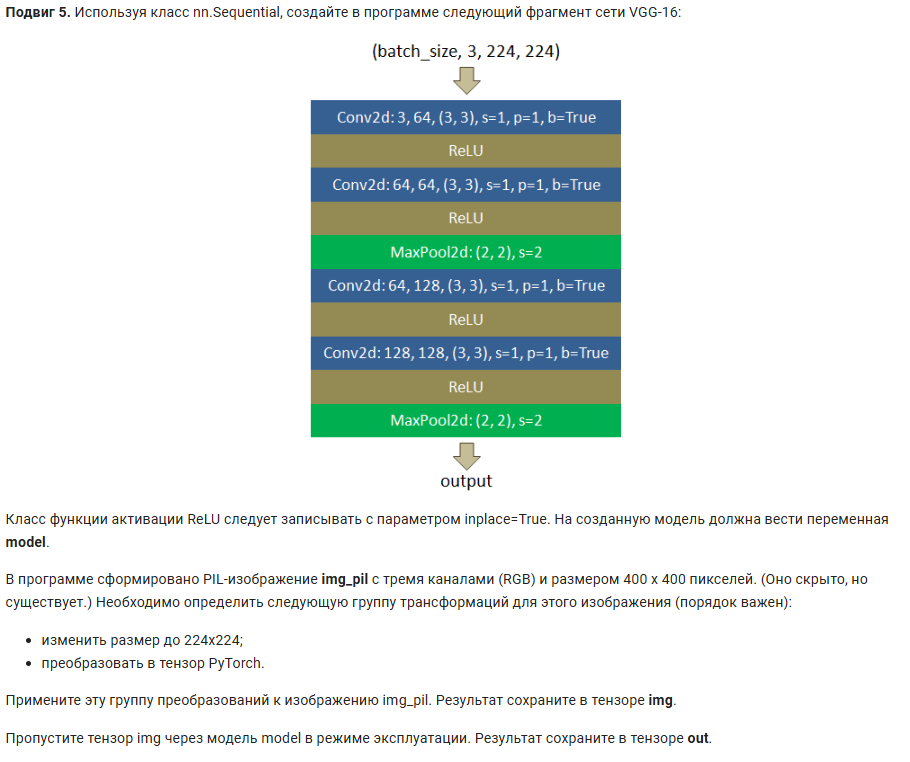

In [16]:
import torch
import torchvision.transforms as tfs
import torch.nn as nn
from PIL import Image

# здесь продолжайте программу
model = nn.Sequential(
        nn.Conv2d(in_channels=3, out_channels=64, kernel_size =(3, 3), stride=1, padding=1, bias=True),
        nn.ReLU(inplace=True),
    
        nn.Conv2d(in_channels=64, out_channels=64, kernel_size =(3, 3), stride=1, padding=1, bias=True),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(kernel_size=(2, 2), stride=2),
    
        nn.Conv2d(in_channels=64, out_channels=128, kernel_size =(3, 3), stride=1, padding=1, bias=True),
        nn.ReLU(inplace=True),
    
        nn.Conv2d(in_channels=128, out_channels=128, kernel_size =(3, 3), stride=1, padding=1, bias=True),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(kernel_size=(2, 2), stride=2),
)

transforms = tfs.Compose([
    tfs.Resize(224),
    tfs.ToTensor()
])


try:
    img = transforms(img_pil)
except:
    img_pil =Image.open('puli.jpg').convert('RGB')
    img = transforms(img_pil)

model.eval()
out = model(img.unsqueeze(0))
out.shape

torch.Size([1, 128, 56, 77])

In [12]:
transforms = tfs.Compose([
    tfs.Resize(256),
    tfs.ToTensor()
])

transforms(img_pil)

tensor([[[0.5216, 0.5294, 0.5569,  ..., 0.1843, 0.1922, 0.1882],
         [0.5294, 0.5176, 0.5294,  ..., 0.2039, 0.1882, 0.1804],
         [0.5451, 0.5412, 0.5569,  ..., 0.1843, 0.1647, 0.1686],
         ...,
         [0.5255, 0.5569, 0.5608,  ..., 0.5451, 0.5294, 0.4941],
         [0.5451, 0.5647, 0.5294,  ..., 0.5608, 0.5608, 0.5608],
         [0.4510, 0.3961, 0.4078,  ..., 0.5373, 0.5961, 0.6353]],

        [[0.6824, 0.6902, 0.7176,  ..., 0.2471, 0.2510, 0.2627],
         [0.6980, 0.6784, 0.6784,  ..., 0.2275, 0.2157, 0.2353],
         [0.7098, 0.6980, 0.6980,  ..., 0.2196, 0.2000, 0.2353],
         ...,
         [0.5725, 0.5804, 0.5804,  ..., 0.5373, 0.5294, 0.4824],
         [0.5961, 0.5961, 0.5686,  ..., 0.5490, 0.5686, 0.5725],
         [0.4824, 0.4314, 0.4549,  ..., 0.5490, 0.6039, 0.6627]],

        [[0.3255, 0.3333, 0.3922,  ..., 0.1647, 0.1725, 0.1529],
         [0.3608, 0.3412, 0.3608,  ..., 0.1608, 0.1529, 0.1529],
         [0.4039, 0.4039, 0.4275,  ..., 0.1373, 0.1137, 0.

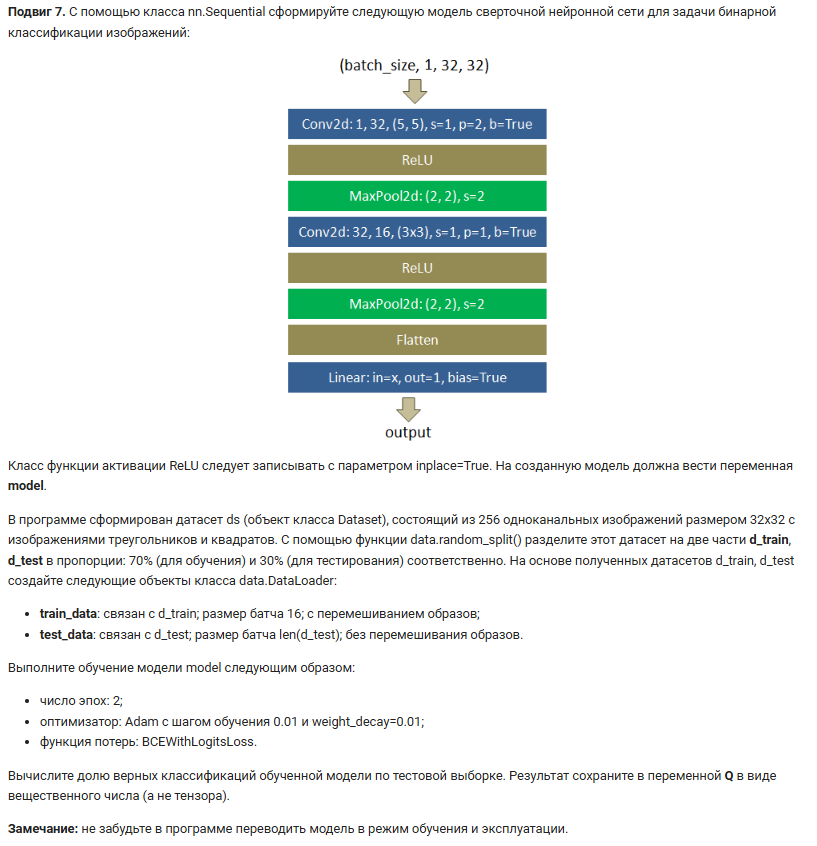

In [52]:
import torch
import torch.nn as nn
import torch.utils.data as data
import torch.optim as optim

import torch.utils.data as data
import torch

class MyselfData(data.Dataset):
    def __init__(self):
        self.data = torch.rand((256, 1, 32, 32)) * 256
        self.target = torch.randint(0, 2, (256,)).float()
        self.length = self.data.shape[0]

    def __getitem__(self, item):
        return self.data[item], self.target[item]

    def __len__(self):
        return self.length
    
ds = MyselfData()

d_train, d_test = data.random_split(ds, (0.7, 0.3))

train_data = data.DataLoader(d_train, batch_size=16, shuffle=True)
test_data = data.DataLoader(d_test, batch_size=len(d_test), shuffle=False)

# здесь продолжайте программу
model = nn.Sequential(
        nn.Conv2d(in_channels=1, out_channels=32, kernel_size =(5, 5), stride=1, padding=2, bias=True),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(kernel_size=(2, 2), stride=2),
    
        nn.Conv2d(in_channels=32, out_channels=16, kernel_size =(3, 3), stride=1, padding=1, bias=True),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(kernel_size=(2, 2), stride=2),

        nn.Flatten(),
        nn.Linear(in_features=1024, out_features=1, bias=True)
)

epochs = 2
optimizer= optim.Adam(model.parameters(), lr=0.01, weight_decay=0.01)
loss_func = nn.BCEWithLogitsLoss()

for e in range(epochs):
    model.eval()
    for x_train, y_train in train_data:
        optimizer.zero_grad()
        pred = model(x_train).squeeze(1)
        loss = loss_func(pred, y_train)
        loss.backward()
        optimizer.step()

model.eval()
x_test, y_test = next(iter(test_data))
pred = model(x_test).squeeze(1)
Q = loss_func(pred, y_test).item()
Q

0.6938514709472656